# Supplementary figure: regression of scan structure

A single-subject worked example, for supplementary section *Regression of scan structure*
(`sfig:example_timeseries`).

In [1]:
import os
import warnings
warnings.simplefilter("ignore", UserWarning)
warnings.simplefilter(action='ignore', category=FutureWarning)

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

%matplotlib inline

from src.data import DataLoader
from src.timescales import Timescales, split_design_columns, drift_only_control
# INT estimation comes from snaplab_tools; src.timescales owns only the caching layer.
from snaplab_tools.timescales import compute_acf, TIMESCALE_METHODS
from src.supporting_data import load_supporting_data
from src.plotting import plot_task_regression_example, figure_scratch_dir, setup_notebook_style
from snaplab_tools.plotting.utils import save_panel

setup_notebook_style()

In [2]:
dataset      = 'HCP-YA'
task_scan    = 'tfMRIWMLR'   # working memory: blocked, 8 x 27.5 s blocks, TR 0.72 s
n_regions    = 400
seg          = 'Schaefer4007'
space        = 'fsLR'
session      = '01'
modality     = 'MRI3T'

# The INT estimator used throughout the main text.
int_method   = 'auc_zero_crossing'
output_type  = f'timescale_{int_method}'

# Set to a subject ID (e.g. '214423') to pin the example; None selects the median
# subject in the next cell.
example_subject = None

## Choose the example subject

A "single subject" figure invites the question of whether the subject was picked to flatter the
argument. So the choice is made from the already-cached group results and stated: the subject
whose INT reduction is closest to the **median** across everyone with this scan. The cell prints
the group distribution, so the caption can report where the example sits in it.

In [3]:
selector = Timescales(dataset=dataset, timeseries_data=None, load_behavior=False, verbose=False)
selector.load_scan_registry(f'scan_registry_{dataset}.csv')

# Restrict to this task before loading, so we read ~1k cached files rather than ~15k.
selector.scan_registry = [s for s in selector.scan_registry if s.task == task_scan]

selector.get_precomputed_outputs(output_type=output_type)
cached_before = dict(selector.data_dict)
selector.get_precomputed_outputs(output_type=f'{output_type}_resids')
cached_after = dict(selector.data_dict)

rows = []
for scan_key, before in cached_before.items():
    after = cached_after.get(scan_key)
    if before is None or after is None:
        continue
    before, after = np.asarray(before, float), np.asarray(after, float)
    ok = np.isfinite(before) & np.isfinite(after)
    if ok.sum() < n_regions // 2:   # a scan where most regions have no zero crossing
        continue
    rows.append({
        'scan_key': scan_key,
        'sub':      selector._parse_scan_string(scan_key)['sub'],
        'int_before': np.nanmean(before[ok]),
        'int_after':  np.nanmean(after[ok]),
    })

df_group = pd.DataFrame(rows)
df_group['delta'] = df_group['int_after'] - df_group['int_before']

print(f'{len(df_group)} usable {task_scan} scans')
print(f"  INT before: {df_group['int_before'].mean():.3f} +/- {df_group['int_before'].std():.3f} s")
print(f"  INT after:  {df_group['int_after'].mean():.3f} +/- {df_group['int_after'].std():.3f} s")
print(f"  change:     median {df_group['delta'].median():.3f} s, "
      f"{100 * (df_group['delta'] < 0).mean():.1f}% of scans reduced")

Loaded 15456 scans from scan_registry_HCP-YA.csv


Loading timescale_auc_zero_crossing_resids: 100%|██████████| 966/966 [00:00<00:00, 7639.94it/s]

966 usable tfMRIWMLR scans
  INT before: 2.830 +/- 1.006 s
  INT after:  0.875 +/- 0.169 s
  change:     median -1.735 s, 100.0% of scans reduced


In [4]:
if example_subject is None:
    median_delta = df_group['delta'].median()
    pick = df_group.loc[(df_group['delta'] - median_delta).abs().idxmin()]
else:
    pick = df_group.loc[df_group['sub'] == str(example_subject)].iloc[0]

subject_id = pick['sub']
pctile = 100.0 * (df_group['delta'] < pick['delta']).mean()

print(f'example subject: {subject_id}')
print(f"  INT before {pick['int_before']:.3f} s, after {pick['int_after']:.3f} s "
      f"(change {pick['delta']:+.3f} s)")
print(f'  sits at the {pctile:.1f}th percentile of the group change distribution')

example subject: 214423
  INT before 2.667 s, after 0.932 s (change -1.735 s)
  sits at the 50.0th percentile of the group change distribution


## Rebuild that subject's scan

In [5]:
loader = DataLoader(dataset=dataset, load_behavior=False, verbose=False)
loader.register_scans(subject_ids=[subject_id], sessions=[session], tasks=[task_scan],
                      space=space, seg=seg, modality=modality)

timeseries_data = loader.load_batch(detrend=True, nuisance_regression=True,
                                    frequency_filter=False, verbose=True)

scan_key = list(timeseries_data)[0]
tr = float(loader.get_tr(modality))
print(f'{scan_key}\n  shape {timeseries_data[scan_key].shape}, TR {tr} s')

Loading 1 scans...
  [1/1] 214423 tfMRIWMLR

Loaded: 1/1 scans
sub-214423_task-tfMRIWMLR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task
  shape (400, 405), TR 0.72 s


In [6]:
processor = Timescales(dataset=dataset, timeseries_data=timeseries_data,
                       load_behavior=False, verbose=False)
processor.regress_task_structure()

raw_data      = processor.timeseries_data[scan_key]
residual_data = processor.timeseries_residuals[scan_key]
design_matrix = processor.design_matrices[scan_key]
task_events   = processor.task_events[scan_key]
design_flat   = processor.task_regressor_flat[scan_key]   # all conditions merged into one
acf_design    = processor.task_events_acf[scan_key]       # ACF of that flattened regressor

if residual_data is None:
    raise RuntimeError(f'task regression failed for {scan_key}')

task_cols, nuisance_cols = split_design_columns(design_matrix)
print(f'{len(task_cols)} task regressors: {task_cols}')
print(f'{len(nuisance_cols)} nuisance columns: {nuisance_cols}')
print(f'{len(task_events)} blocks, {task_events["duration"].iloc[0]:.1f} s each')
display(task_events)

Regressing task structure out of timeseries: 100%|██████████| 1/1 [00:00<00:00,  5.03it/s]


8 task regressors: ['0bk_body', '0bk_faces', '0bk_places', '0bk_tools', '2bk_body', '2bk_faces', '2bk_places', '2bk_tools']
6 nuisance columns: ['drift_1', 'drift_2', 'drift_3', 'drift_4', 'drift_5', 'constant']
8 blocks, 27.5 s each


,onset,duration,trial_type
0,36.131,27.5,0bk_body
1,221.961,27.5,0bk_faces
2,250.283,27.5,0bk_places
3,107.462,27.5,0bk_tools
4,150.537,27.5,2bk_body
5,79.233,27.5,2bk_faces
6,178.672,27.5,2bk_places
7,7.996,27.5,2bk_tools


In [7]:
# The "after" side: the full-GLM residual's INT, which the assertion below checks against the cached value.
acf_after = compute_acf(residual_data, use_fft=True)
int_fn    = TIMESCALE_METHODS[int_method]
int_after = int_fn(acf_after, tr)

# The "before" side regresses out only drift and the constant, so the contrast between the two sides is the
# task regressors alone.
drift = drift_only_control(raw_data, design_matrix, tr, int_method=int_method)
baseline_data = drift['residual']
acf_baseline  = drift['acf']
int_baseline  = drift['int_drift']
int_raw       = drift['int_raw']

print(f"INT raw (as loaded)  {np.nanmean(int_raw):.3f} s")
print(f"INT baseline (drift) {np.nanmean(int_baseline):.3f} s")
print(f"INT after (full GLM) {np.nanmean(int_after):.3f} s")
print(f"cost of the drift basis alone: median {drift['median']:+.3f} s "
      f"(IQR [{drift['q25']:+.3f}, {drift['q75']:+.3f}], n = {drift['n_valid']} regions) "
      f"-- this is what the old raw-vs-residual contrast was charging to task regression")
print(f"task regressors alone:         median "
      f"{np.nanmedian(int_after - int_baseline):+.3f} s")

# Check that this scan reproduces the cached group values (raw and residual INT), so the figure illustrates
# the published pipeline.
np.testing.assert_allclose(np.nanmean(int_raw),   pick['int_before'], rtol=1e-6)
np.testing.assert_allclose(np.nanmean(int_after), pick['int_after'],  rtol=1e-6)
print('reproduces the cached group values')

INT raw (as loaded)  2.667 s
INT baseline (drift) 1.905 s
INT after (full GLM) 0.932 s
cost of the drift basis alone: median -0.495 s (IQR [-0.934, -0.188], n = 400 regions) -- this is what the old raw-vs-residual contrast was charging to task regression
task regressors alone:         median -0.735 s
reproduces the cached group values


In [8]:
supporting_data = load_supporting_data(
    os.path.join(loader.output_dir, 'data', 'supporting_data'), n_regions=n_regions)
sa_axis = supporting_data['df_neuro']['SA_Axis'].values
print('S-A axis:', sa_axis.shape, f'ranks {sa_axis.min():.0f}-{sa_axis.max():.0f}')

	Brain-gene panel 'gao': 2031/2429 symbols present in the expression matrix -> PCA input (400, 2031).
S-A axis: (400,) ranks 1-400


## Draw the figure

/mnt/lindenmp_nas/lindenmp/work/figure_scratch/intrinsic_neural_timescales/HCP-YA/sfig_task_regression_HCP-YA_sub-214423_tfMRIWMLR


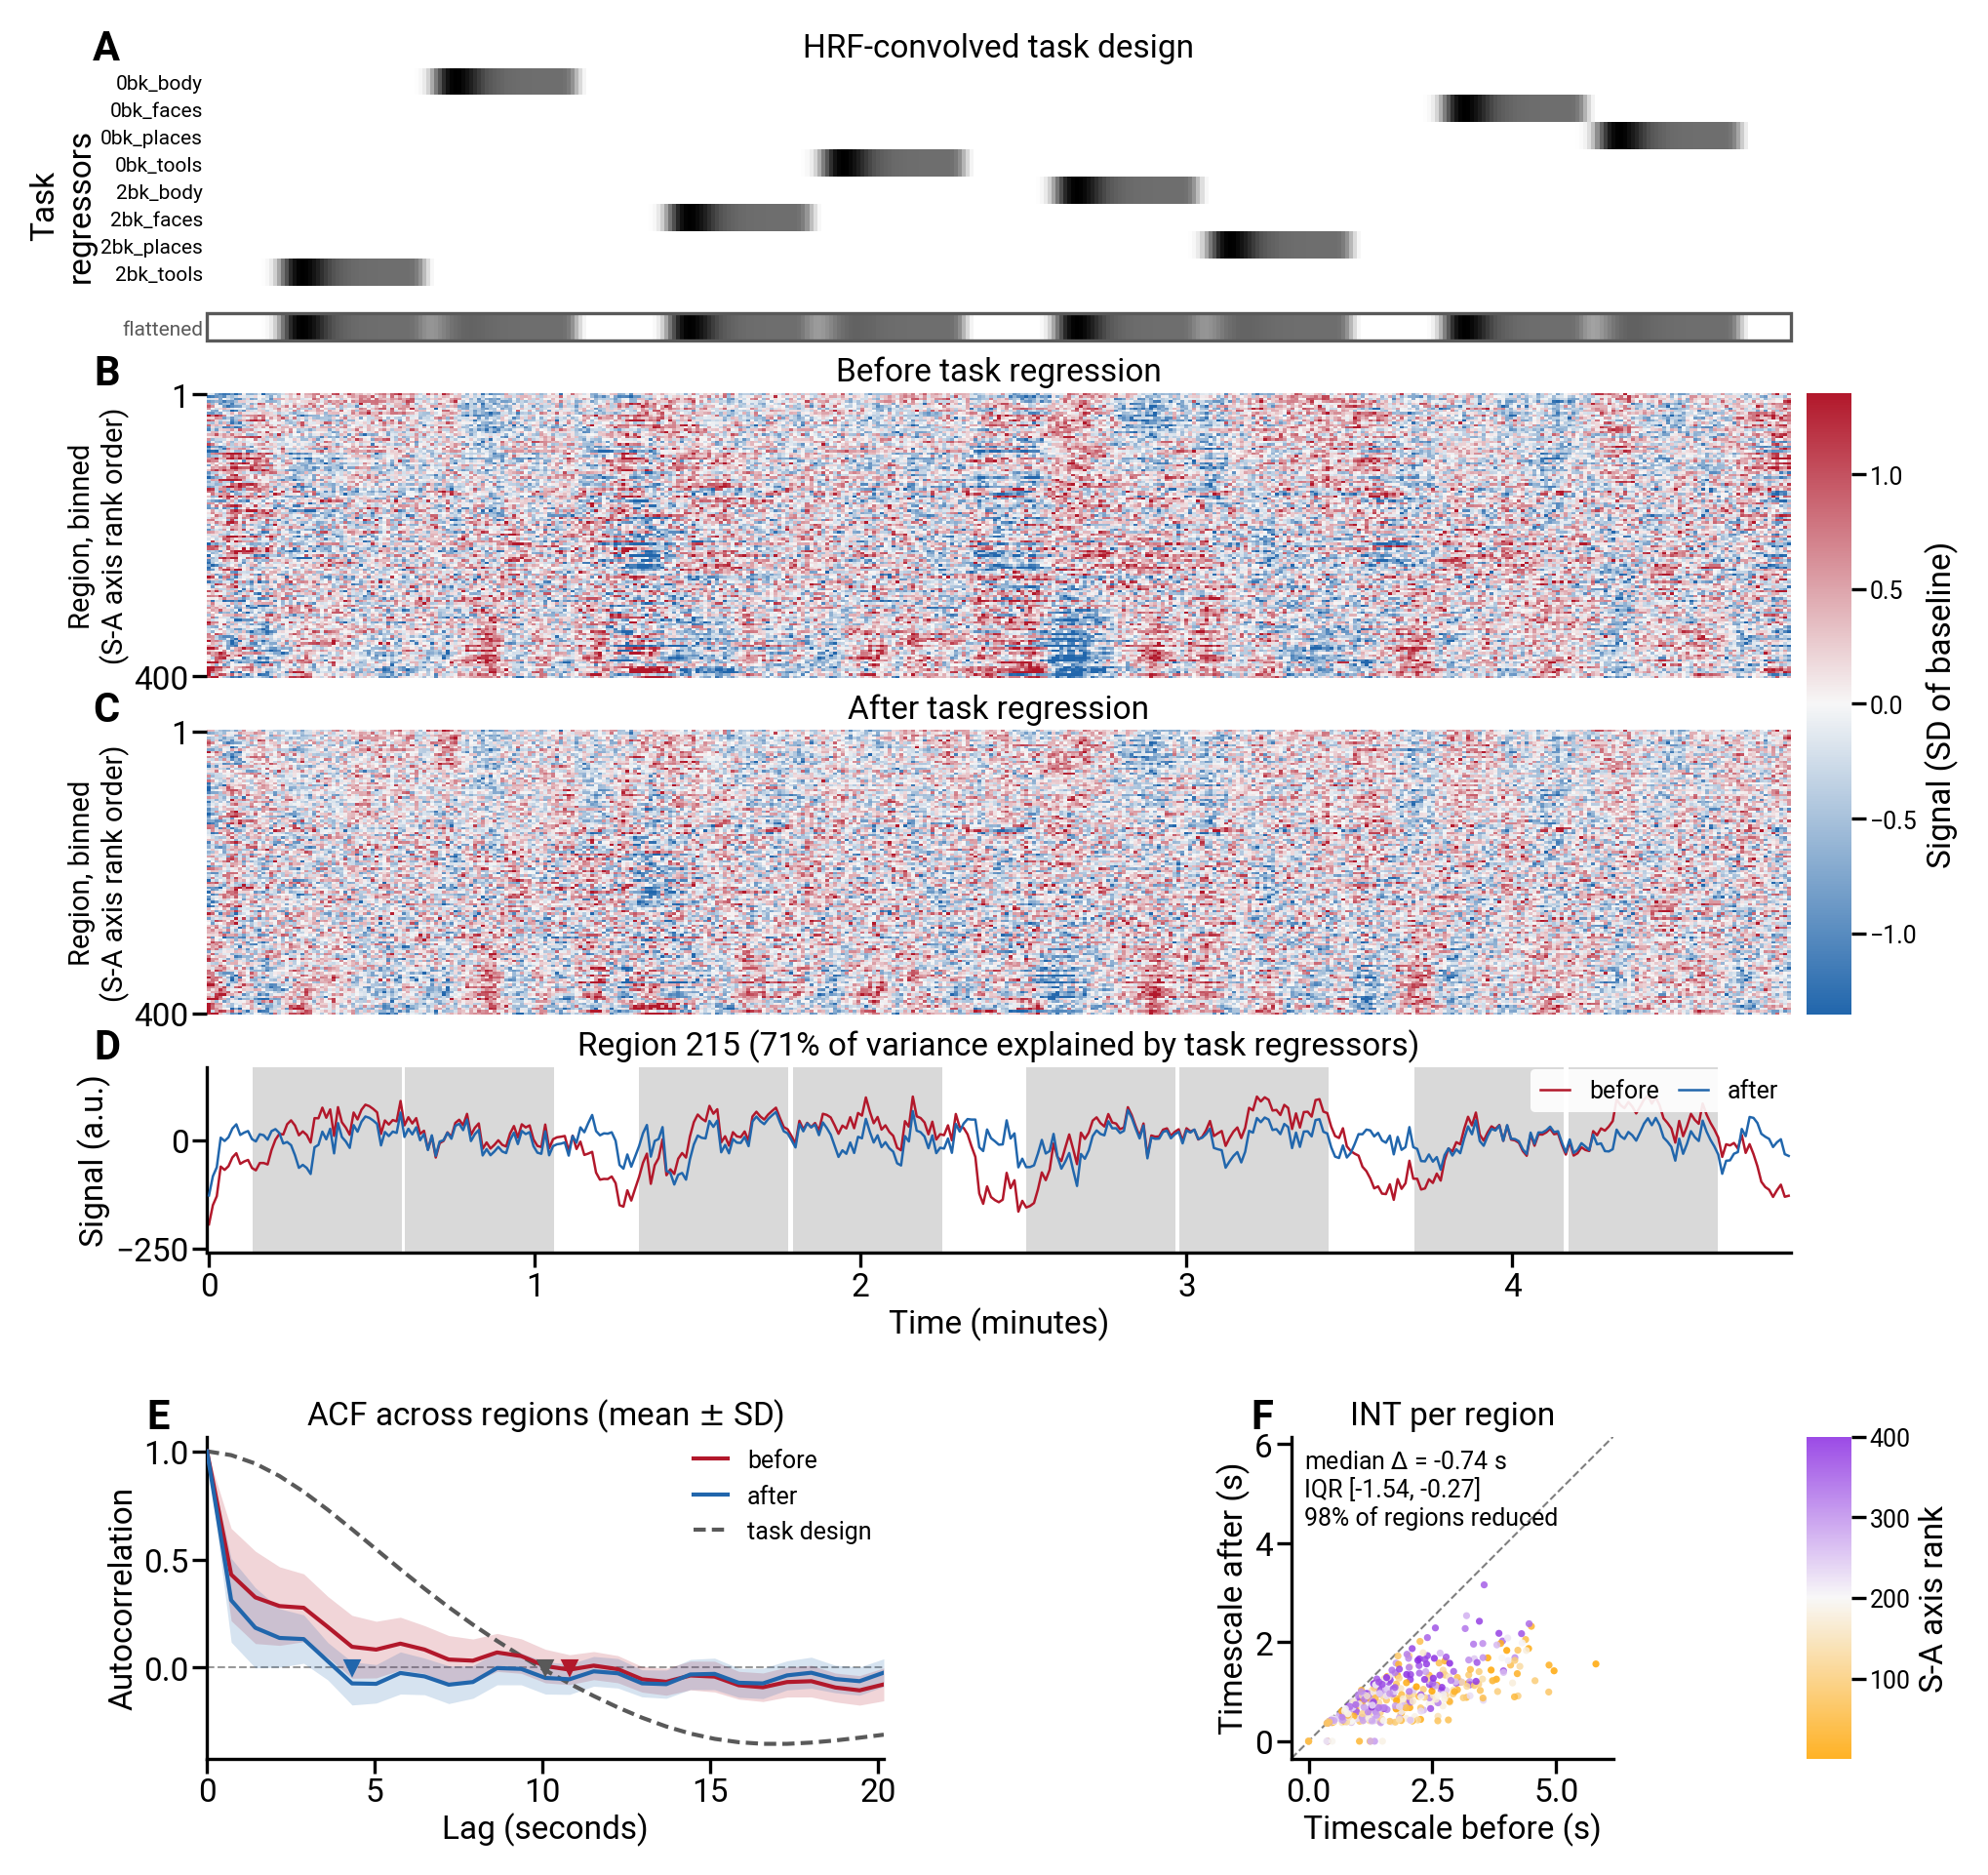

In [9]:
fig, axes, stats = plot_task_regression_example(
    baseline_data=baseline_data,
    residual_data=residual_data,
    design_matrix=design_matrix,
    acf_baseline=acf_baseline,
    acf_resid=acf_after,
    acf_design=acf_design,
    int_baseline=int_baseline,
    int_resid=int_after,
    tr=tr,
    task_events=task_events,
    design_flat=design_flat,
    brain_map=sa_axis,
    max_lag_seconds=20.0,
)

fig_dir = figure_scratch_dir(dataset)
# 120 binned imshow rows x 405 columns, twice -- worth more than the 300 dpi a line panel needs.
print(save_panel(fig, fig_dir,
                 f'sfig_task_regression_{dataset}_sub-{subject_id}_{task_scan}', dpi=400))
plt.show()